In [3]:
# !ffmpeg -y -loglevel error -i audio/noise_recording.m4a -ac 1 -ar 44100 -c:a pcm_s16le audio/noise_recording.wav

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import IPython.display as ipd

# Clean Signal

In [10]:
fs_clean, clean_signal = wavfile.read("./audio/clean_speech.wav")
t_clean = np.arange(len(clean_signal)) / fs_clean

print("fs =",fs_clean)
print("Samples =",len(clean_signal))
print("Duration =",len(clean_signal)/fs_clean,"s")
print("signal shape =", clean_signal.shape) #mono signal, 1 channel
print("signal dtype =", clean_signal.dtype)

fs = 16000
Samples = 172343
Duration = 10.7714375 s
signal shape = (172343,)
signal dtype = int16


In [12]:
# int16 can store -32768 to 32767 -> convert to float before adding noise
clean = clean_signal.astype(np.float64)        # step 1: cast to float
clean = clean / np.max(np.abs(clean))          # step 2: peak normalize to [-1, 1]

print(clean.dtype, clean.min(), clean.max())   # should be float64, about -1 to 1

float64 -1.0 0.8294639276324585


Text(0.5, 1.0, 'original clean_signal after peak_normalization')

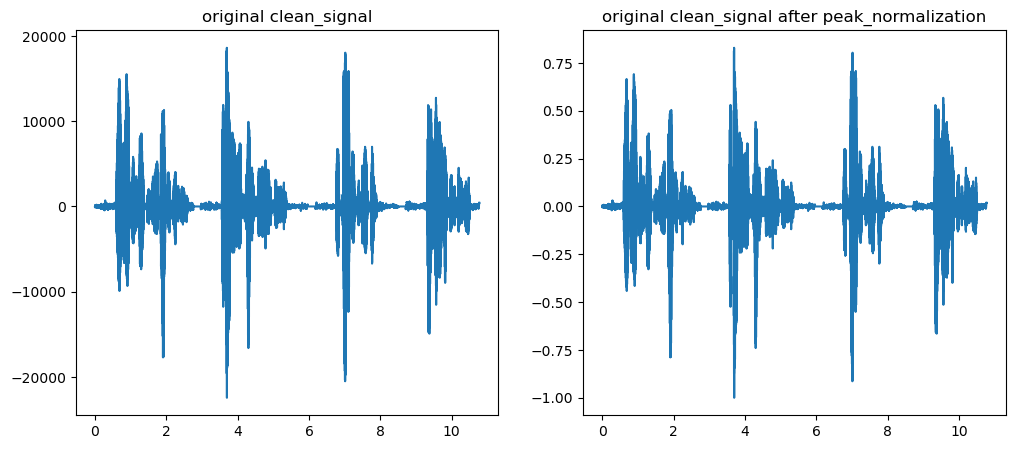

In [19]:
# print(clean)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_clean, clean_signal); plt.title("original clean_signal")
plt.subplot(1, 2, 2); plt.plot(t_clean, clean); plt.title("original clean_signal after peak_normalization")

# Noise Signal

In [20]:
fs_noise, noise_signal = wavfile.read("./audio/noise_recording.wav")
t_noise = np.arange(len(noise_signal)) / fs_noise

print("fs =",fs_noise)
print("Samples =",len(noise_signal))
print("Duration =",len(noise_signal)/fs_noise,"s")
print("signal shape =", noise_signal.shape) #mono signal, 1 channel
print("signal dtype =", noise_signal.dtype)

fs = 44100
Samples = 587001
Duration = 13.310680272108844 s
signal shape = (587001,)
signal dtype = int16


In [34]:
noise = noise_signal.astype(np.float64)
noise = noise / np.max(np.abs(noise))

Text(0.5, 1.0, 'original noise_signal after peak_normalization')

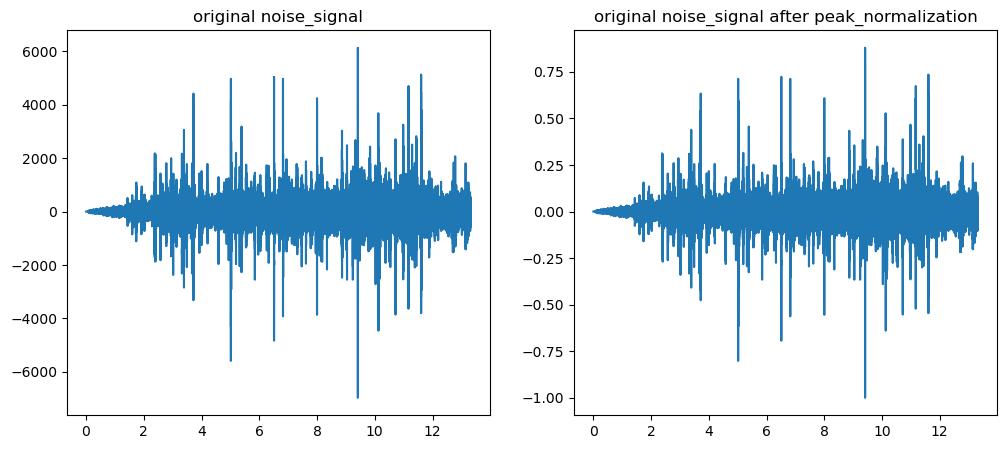

In [35]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_noise, noise_signal); plt.title("original noise_signal")
plt.subplot(1, 2, 2); plt.plot(t_noise, noise); plt.title("original noise_signal after peak_normalization")

# Adding noise to clean signal

In [36]:
noise = noise[fs_noise*2:len(clean)+fs_noise*2]
print(len(noise), len(clean))   # both numbers should be the same

172343 172343


In [42]:
noise_level = 0.5               # the number that controls how loud the noise is

noisy_speech = clean + noise_level * noise

Clean


Noisy


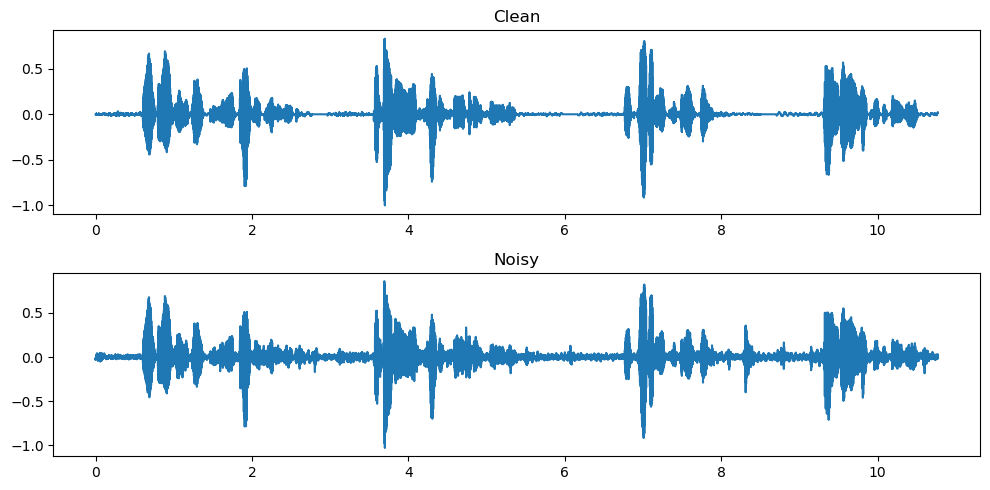

In [43]:
print("Clean")
ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy")
ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))

plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1); plt.plot(t_clean, clean); plt.title("Clean")
plt.subplot(2, 1, 2); plt.plot(t_clean, noisy_speech); plt.title("Noisy")
plt.tight_layout()
plt.show()

In [47]:
# save the noisy_speech
import os
os.makedirs("./audio/audio_run", exist_ok=True)       # make the folder if it doesn't exist

noisy_save = noisy_speech / max(1, np.max(np.abs(noisy_speech)))   # only shrinks it if it goes above 1
wavfile.write("./audio/audio_run/noisy_speech.wav", fs_clean, (noisy_save * 32767).astype(np.int16))